# Dataset 1 — University Student Stress: EDA and Feature Screening

**Revised from your original `01_dataset1_eda(1).ipynb`.** The original data inspection, stress plots, score-construction check, and optional association methods are retained, with a new step-by-step factor review and selection stage.

**Workflow:** Load → check quality → inspect stress labels → examine **every input factor** → compare patterns → record a **provisional** feature shortlist → summarize and visualize selected features.

**Important:** Stress_Level is constructed from Stress_Score. Associations with its ingredients can reflect the label-building rule rather than independently reported stress. We do **not** train a model or claim final feature importance here.

## 0 — Setup
Install dependencies **only if imports fail** (uncomment the command below). After installing, restart the kernel if required.

In [1]:
# %pip install pandas numpy matplotlib seaborn scipy

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import chi2_contingency, spearmanr

In [3]:
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 5), "axes.titlesize": 12})
# Works from /notebooks, project root, or when notebook and data folder are copied together.
file_path = Path.cwd().parent / 'data' / 'raw' / 'dataset1.csv'
assert file_path.exists(), f"Data file missing: {file_path}"
df = pd.read_csv(file_path)
target = 'Stress_Level'
print(f"Loaded: {file_path.name} | Rows: {len(df):,} | Columns: {df.shape[1]}")
display(df.head())

Loaded: dataset1.csv | Rows: 3,000 | Columns: 18


,Age,Gender,Study_Hours,Class_Attendance,Tuition,Exam_Frequency,Assignment_Load,Sleep_Hours,Physical_Exercise,Social_Media_Use,Screen_Time,Family_Income_Level,Peer_Pressure,Family_Support,Anxiety_Level,University_Type,Stress_Score,Stress_Level
0,24,Male,9,71,No,7,4,6,Yes,6,9,Low,6,3,5,National University,20,Medium
1,24,Female,8,43,Yes,6,8,5,Yes,6,8,Medium,3,7,8,National University,22,High
2,21,Female,4,56,Yes,3,6,5,Yes,7,9,Low,2,5,3,Private University,16,Medium
3,23,Female,4,46,No,8,6,8,No,5,6,Medium,8,6,5,Private University,16,Medium
4,20,Male,8,46,No,5,1,6,Yes,0,7,Medium,5,6,2,National University,1,Low


## 1 — Data understanding and quality
Inspect column meanings, types, missingness, and exact duplicates. Survey categories are **not** outliers just because they are rare. Exclude identifiers and responses that would leak the target when planning a prediction model.

In [4]:
display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values, "missing": df.isna().sum().values, "unique": df.nunique(dropna=False).values}))
print("Shape:", df.shape)
print("Missing cells:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
display(df.describe(include="all").T)

,column,dtype,missing,unique
0,Age,int64,0,6
1,Gender,object,0,2
2,Study_Hours,int64,0,10
3,Class_Attendance,int64,0,60
4,Tuition,object,0,2
5,Exam_Frequency,int64,0,9
6,Assignment_Load,int64,0,9
7,Sleep_Hours,int64,0,6
8,Physical_Exercise,object,0,2
9,Social_Media_Use,int64,0,8


Shape: (3000, 18)
Missing cells: 0
Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,3000.0,NaN,NaN,NaN,21.517333,1.705678,19.0,20.0,21.0,23.0,24.0
Gender,3000,2,Female,1538,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Study_Hours,3000.0,NaN,NaN,NaN,4.488667,2.858659,0.0,2.0,4.0,7.0,9.0
Class_Attendance,3000.0,NaN,NaN,NaN,68.872333,17.442576,40.0,54.0,69.0,84.0,99.0
Tuition,3000,2,No,1545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Exam_Frequency,3000.0,NaN,NaN,NaN,5.025667,2.592023,1.0,3.0,5.0,7.0,9.0
Assignment_Load,3000.0,NaN,NaN,NaN,4.996,2.594654,1.0,3.0,5.0,7.0,9.0
Sleep_Hours,3000.0,NaN,NaN,NaN,6.519,1.687381,4.0,5.0,7.0,8.0,9.0
Physical_Exercise,3000,2,No,1551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Social_Media_Use,3000.0,NaN,NaN,NaN,3.487,2.288721,0.0,2.0,3.0,5.0,7.0


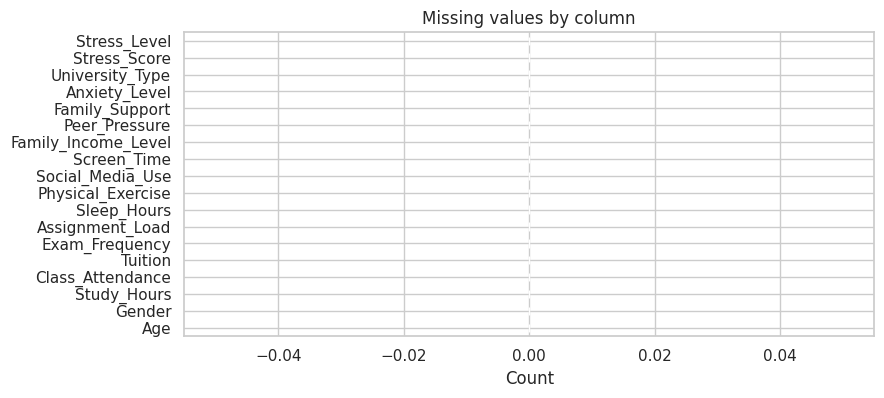

In [5]:
missing = df.isna().sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, max(3, min(9, len(df.columns)*.23))))
missing.plot(kind="barh", ax=ax)
ax.set_title("Missing values by column")
ax.set_xlabel("Count")
plt.tight_layout(); plt.show()

## 2 — Stress target and class balance
Check whether a majority-class classifier could appear impressive. Each dataset uses a different stress definition; avoid pooling their raw labels.

,count,percent
Stress_Level,,
Medium,1431,47.70
Low,1243,41.43
High,326,10.87


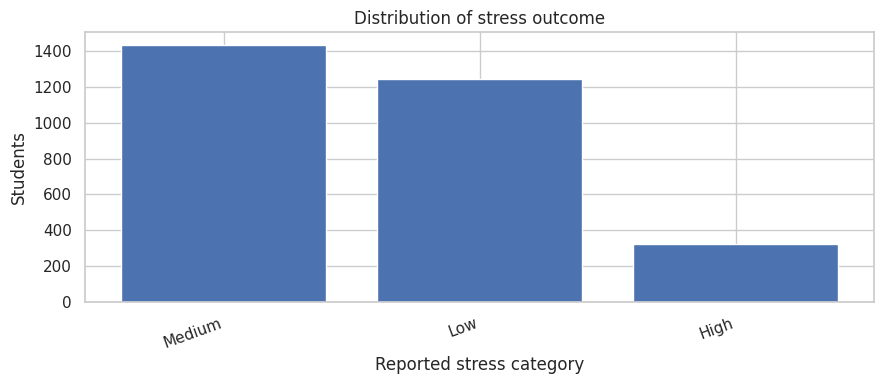

Majority-class share: 47.7%; rarest class: 326 records


In [6]:
counts = df[target].value_counts(dropna=False)
display(pd.DataFrame({"count": counts, "percent": (counts/len(df)*100).round(2)}))
fig,ax = plt.subplots(figsize=(9,4))
ax.bar(counts.index.astype(str), counts.values)
ax.set(title="Distribution of stress outcome", xlabel="Reported stress category", ylabel="Students")
plt.xticks(rotation=20,ha="right"); plt.tight_layout();plt.show()
print(f"Majority-class share: {counts.max()/len(df):.1%}; rarest class: {counts.min()} records")

## 3 — Explore every possible input factor

Here we systematically compare every candidate column against `Stress_Level`. `Stress_Score` is **not** a candidate input because `Stress_Level` is calculated from it. Numerical and categorical data require different plots.

The plots are **exploratory evidence**, not proof of causation or predictive usefulness. In particular, inspecting factors one at a time may miss useful combinations.

In [7]:
# Identify all available candidate factors without silently omitting any columns.
excluded_from_inputs = ["Stress_Level", "Stress_Score"]
candidate_columns = [c for c in df.columns if c not in excluded_from_inputs]
numeric_factors = [c for c in candidate_columns if pd.api.types.is_numeric_dtype(df[c])]
categorical_factors = [c for c in candidate_columns if c not in numeric_factors]
print("Numeric factors:", numeric_factors)
print("Categorical factors:", categorical_factors)
print("Excluded:", excluded_from_inputs)
assert len(candidate_columns) + len(excluded_from_inputs) == len(df.columns)

Numeric factors: ['Age', 'Study_Hours', 'Class_Attendance', 'Exam_Frequency', 'Assignment_Load', 'Sleep_Hours', 'Social_Media_Use', 'Screen_Time', 'Peer_Pressure', 'Family_Support', 'Anxiety_Level']
Categorical factors: ['Gender', 'Tuition', 'Physical_Exercise', 'Family_Income_Level', 'University_Type']
Excluded: ['Stress_Level', 'Stress_Score']


### 3A — Numerical factors: boxplot against stress categories
For each factor, examine **median** (middle line), **spread** (box), and **overlap** between Low, Medium, and High. Strong overlap does not automatically mean the factor is useless.

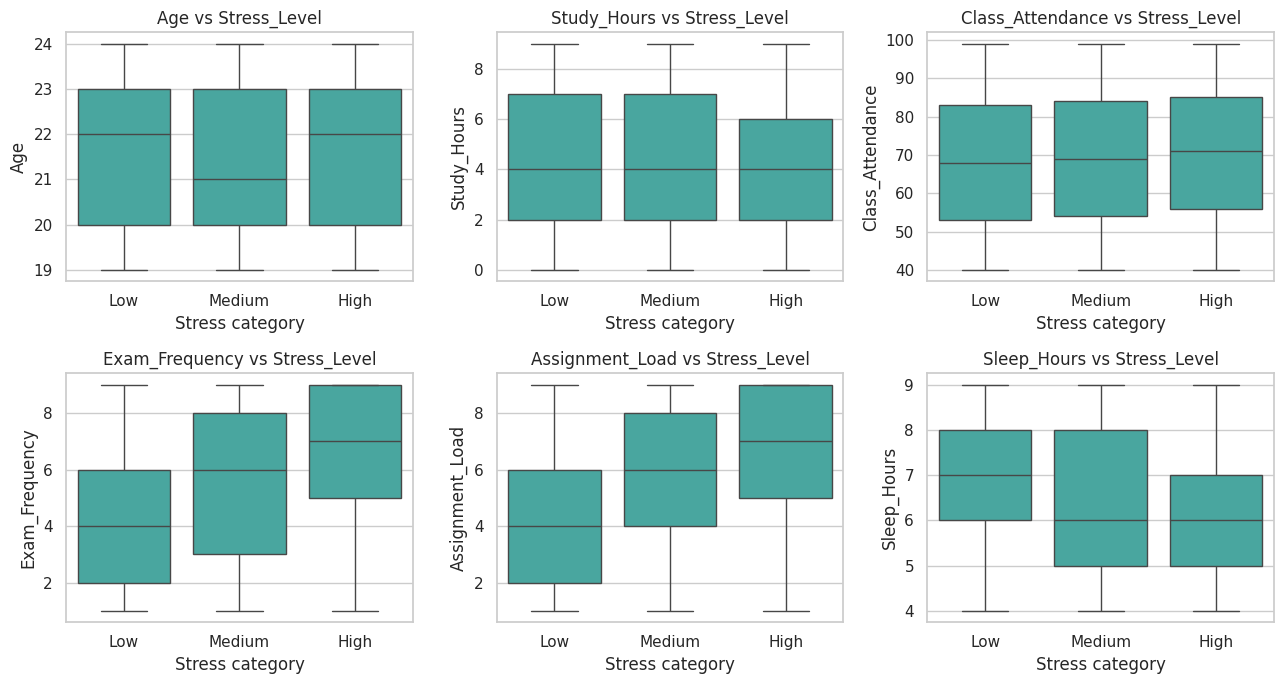

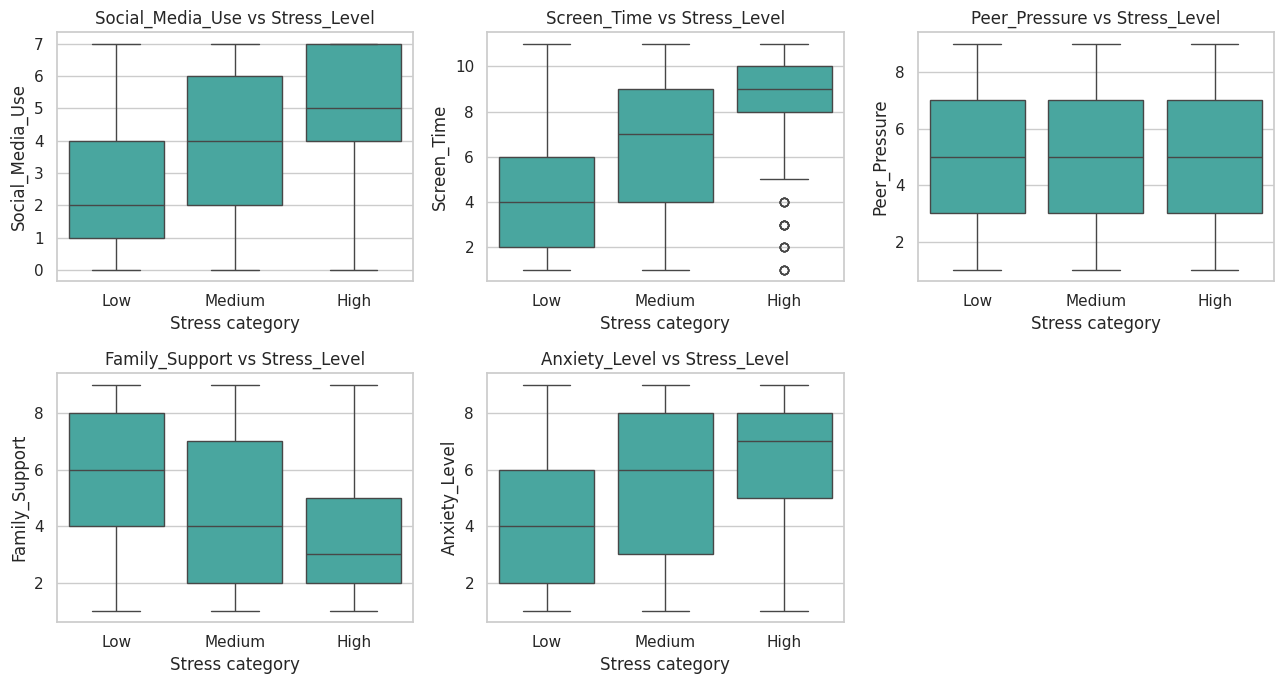

In [8]:
import math
levels = [x for x in ["Low", "Medium", "High"] if x in df["Stress_Level"].unique()]
for start in range(0, len(numeric_factors), 6):
    batch = numeric_factors[start:start+6]
    fig, axes = plt.subplots(2, 3, figsize=(13, 7))
    for ax, factor in zip(axes.flat, batch):
        sns.boxplot(data=df, x="Stress_Level", y=factor, order=levels, ax=ax, color="#39b5ac")
        ax.set(title=f"{factor} vs Stress_Level", xlabel="Stress category", ylabel=factor)
    for ax in axes.flat[len(batch):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

In [9]:
# Simple descriptive table for comparison (NOT feature importance).
median_by_stress = df.groupby("Stress_Level")[numeric_factors].median().reindex(levels).T
print("Medians by stress group (numeric factors):")
display(median_by_stress.round(2))

Medians by stress group (numeric factors):


Stress_Level,Low,Medium,High
Age,22.0,21.0,22.0
Study_Hours,4.0,4.0,4.0
Class_Attendance,68.0,69.0,71.0
Exam_Frequency,4.0,6.0,7.0
Assignment_Load,4.0,6.0,7.0
Sleep_Hours,7.0,6.0,6.0
Social_Media_Use,2.0,4.0,5.0
Screen_Time,4.0,7.0,9.0
Peer_Pressure,5.0,5.0,5.0
Family_Support,6.0,4.0,3.0


### 3B — Categorical factors: within-group percentage charts
Row percentages compare stress distributions even if categories have different group sizes. A group with very few people is less reliable to interpret.


Gender — group sizes


Stress_Level,Low,Medium,High,Total
Gender,,,,
Female,653,718,167,1538
Male,590,713,159,1462


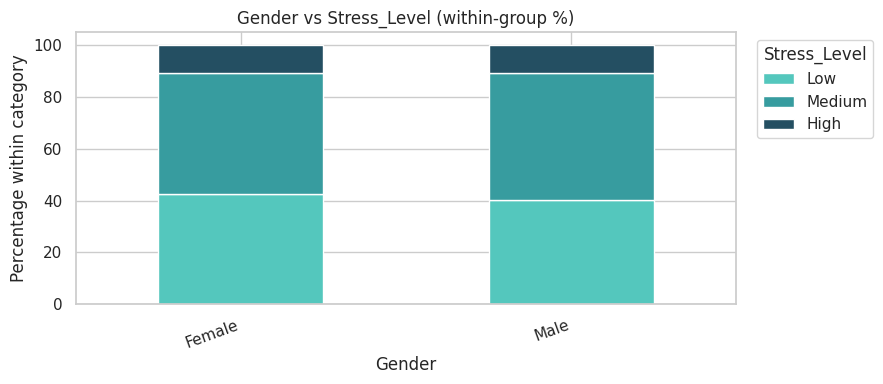


Tuition — group sizes


Stress_Level,Low,Medium,High,Total
Tuition,,,,
No,634,751,160,1545
Yes,609,680,166,1455


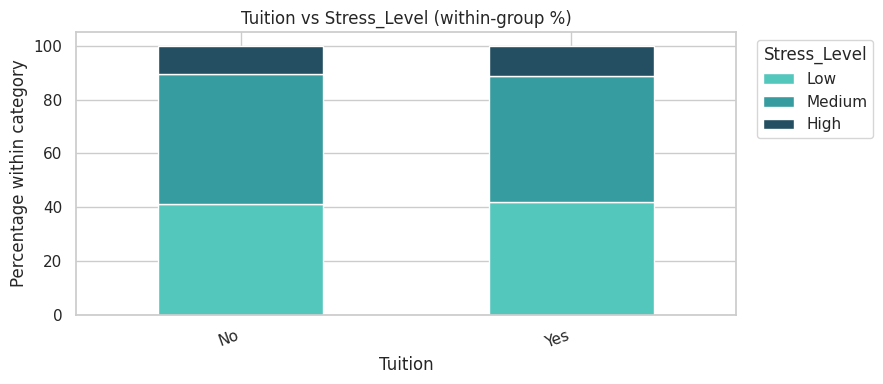


Physical_Exercise — group sizes


Stress_Level,Low,Medium,High,Total
Physical_Exercise,,,,
No,545,801,205,1551
Yes,698,630,121,1449


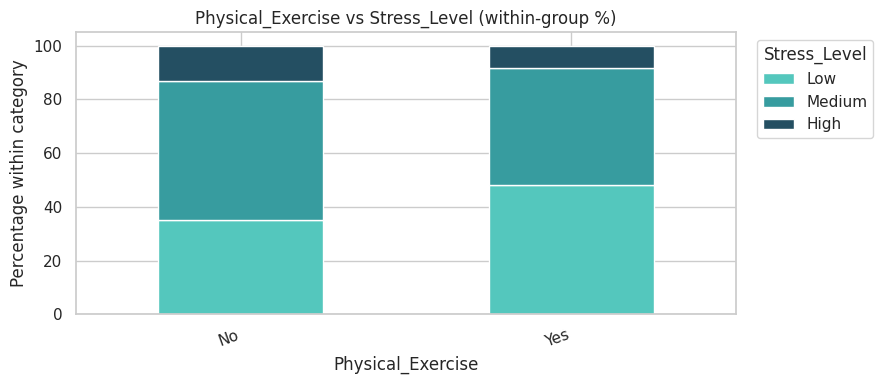


Family_Income_Level — group sizes


Stress_Level,Low,Medium,High,Total
Family_Income_Level,,,,
High,266,272,70,608
Low,427,514,118,1059
Medium,550,645,138,1333


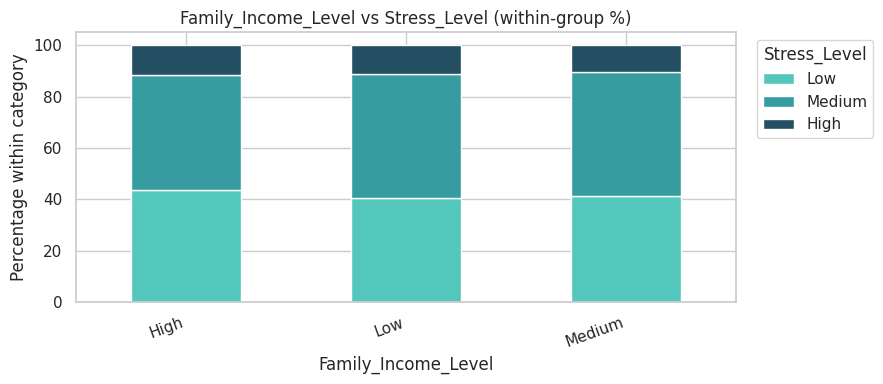


University_Type — group sizes


Stress_Level,Low,Medium,High,Total
University_Type,,,,
National University,417,472,111,1000
Private University,409,494,94,997
Public University,417,465,121,1003


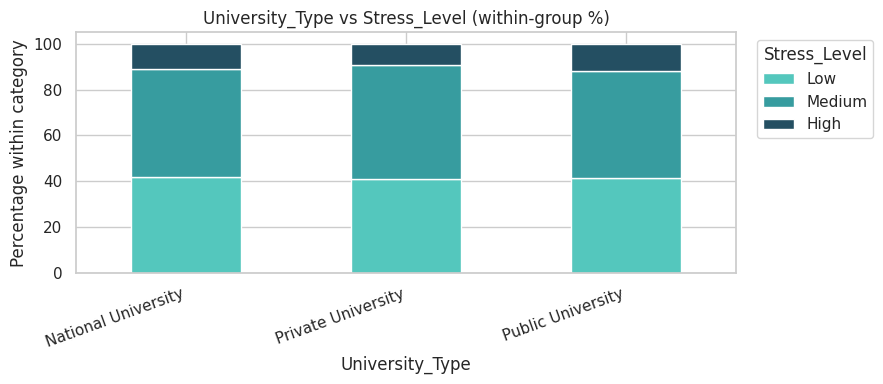

In [10]:
for factor in categorical_factors:
    counts = pd.crosstab(df[factor].fillna("Missing"), df["Stress_Level"])
    counts = counts.reindex(columns=levels, fill_value=0)
    percent = counts.div(counts.sum(axis=1), axis=0).mul(100)
    print(f"\n{factor} — group sizes")
    display(counts.assign(Total=counts.sum(axis=1)))
    ax = percent.plot(kind="bar", stacked=True, figsize=(9,4), color=["#54c7bd", "#379c9f", "#244f62"][:len(levels)])
    ax.set(title=f"{factor} vs Stress_Level (within-group %)", xlabel=factor, ylabel="Percentage within category")
    ax.legend(title="Stress_Level", bbox_to_anchor=(1.02,1), loc="upper left")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()
    if (counts.sum(axis=1) < 10).any():
        print("Caution: one or more groups have fewer than 10 records.")

## 4 — Review all factor relationships before choosing

This stage is **human review guided by visualizations**, not automatic feature elimination. Fill in the blank `Observed_pattern` cells **after looking at the plots**. For each factor, note whether Low / Medium / High distributions differ noticeably or overlap heavily.

The starting decision is based on **project relevance only**. You can adjust it once you review the charts. We exclude `Stress_Score` due to target construction; we retain other features as *candidates*, not verified predictors.

In [11]:
# A review sheet covering EVERY input factor (no automatic removals).
core_lifestyle = {"Sleep_Hours", "Study_Hours", "Screen_Time", "Social_Media_Use",
                  "Physical_Exercise", "Assignment_Load", "Exam_Frequency"}
review = pd.DataFrame({
    "Factor": candidate_columns,
    "Type": ["Numeric" if c in numeric_factors else "Categorical" for c in candidate_columns],
    "Observed_pattern": ["To review from graphs"] * len(candidate_columns),
    "Provisional_decision": ["Candidate: project focus" if c in core_lifestyle else "Consider: needs review" for c in candidate_columns],
    "Reason": ["Lifestyle/academic project relevance" if c in core_lifestyle else "Do not exclude solely for weak single-factor pattern" for c in candidate_columns]
})
display(review)
print("Important exclusion: Stress_Score — used to construct Stress_Level.")

,Factor,Type,Observed_pattern,Provisional_decision,Reason
0,Age,Numeric,To review from graphs,Consider: needs review,Do not exclude solely for weak single-factor p...
1,Gender,Categorical,To review from graphs,Consider: needs review,Do not exclude solely for weak single-factor p...
2,Study_Hours,Numeric,To review from graphs,Candidate: project focus,Lifestyle/academic project relevance
3,Class_Attendance,Numeric,To review from graphs,Consider: needs review,Do not exclude solely for weak single-factor p...
4,Tuition,Categorical,To review from graphs,Consider: needs review,Do not exclude solely for weak single-factor p...
5,Exam_Frequency,Numeric,To review from graphs,Candidate: project focus,Lifestyle/academic project relevance
6,Assignment_Load,Numeric,To review from graphs,Candidate: project focus,Lifestyle/academic project relevance
7,Sleep_Hours,Numeric,To review from graphs,Candidate: project focus,Lifestyle/academic project relevance
8,Physical_Exercise,Categorical,To review from graphs,Candidate: project focus,Lifestyle/academic project relevance
9,Social_Media_Use,Numeric,To review from graphs,Candidate: project focus,Lifestyle/academic project relevance


Important exclusion: Stress_Score — used to construct Stress_Level.


### 4A — Define a provisional shortlist
The following list reflects your project focus; it is **not an empirical ranking**. Add/remove names only after reviewing the plots and documenting reasons. Keep `Stress_Score` out.

In [12]:
selected_factors = [
    "Sleep_Hours", "Study_Hours", "Screen_Time", "Social_Media_Use",
    "Physical_Exercise", "Assignment_Load", "Exam_Frequency"
]
assert all(c in df.columns for c in selected_factors)
assert "Stress_Score" not in selected_factors
print("Selected for further investigation (provisional):")
print(selected_factors)
display(df[selected_factors + ["Stress_Level"]].head())

Selected for further investigation (provisional):
['Sleep_Hours', 'Study_Hours', 'Screen_Time', 'Social_Media_Use', 'Physical_Exercise', 'Assignment_Load', 'Exam_Frequency']


,Sleep_Hours,Study_Hours,Screen_Time,Social_Media_Use,Physical_Exercise,Assignment_Load,Exam_Frequency,Stress_Level
0,6,9,9,6,Yes,4,7,Medium
1,5,8,8,6,Yes,8,6,High
2,5,4,9,7,Yes,6,3,Medium
3,8,4,6,5,No,6,8,Medium
4,6,8,7,0,Yes,1,5,Low


## 5 — Focused visualizations of shortlisted factors
These are the most suitable plots to export for a report or presentation. We show all selected factors using the same comparison approach.

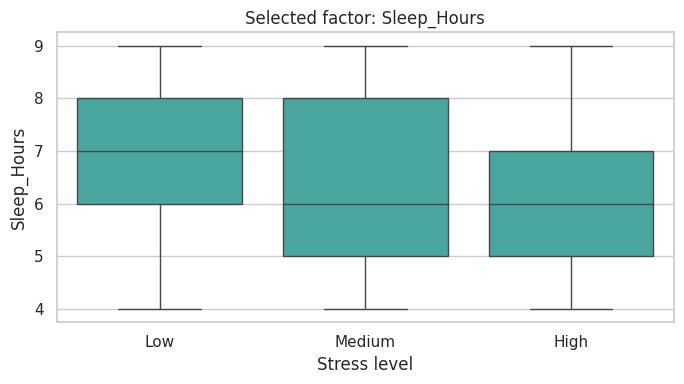

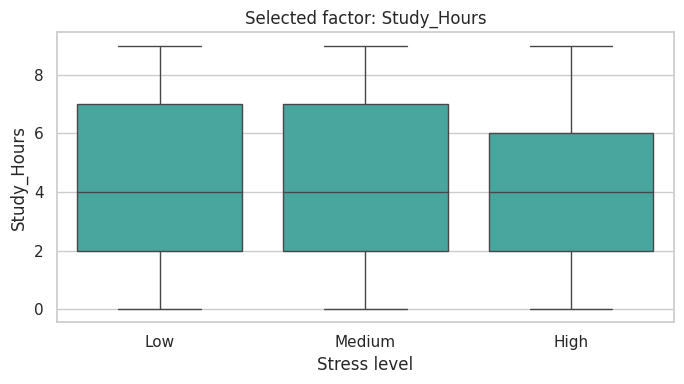

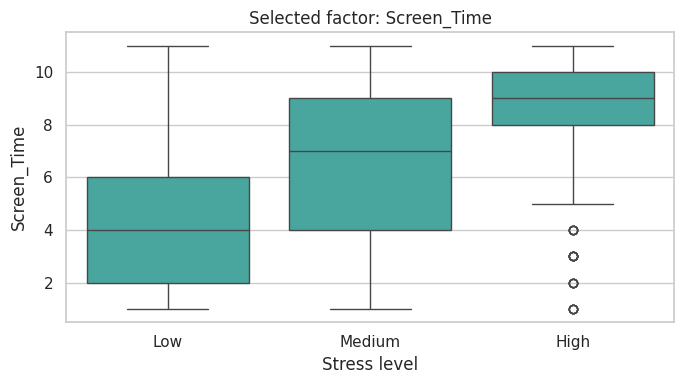

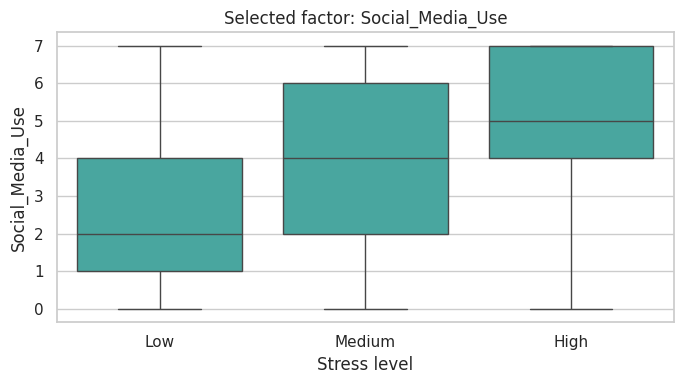

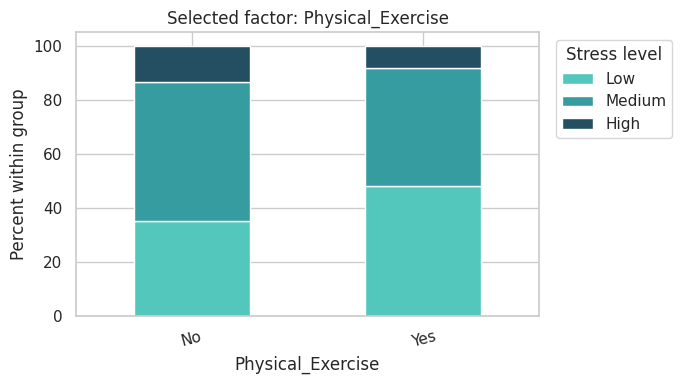

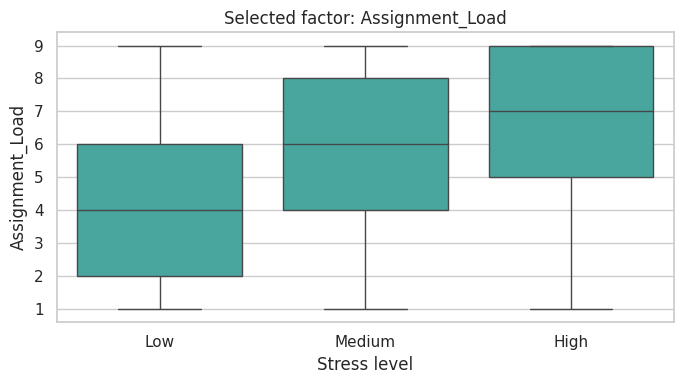

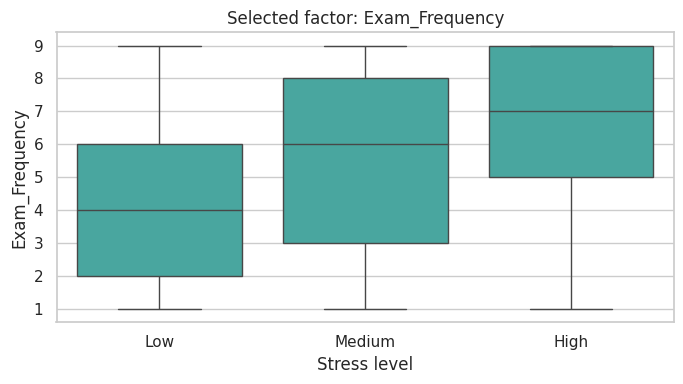

In [13]:
for factor in selected_factors:
    fig, ax = plt.subplots(figsize=(7,4))
    if pd.api.types.is_numeric_dtype(df[factor]):
        sns.boxplot(data=df, x="Stress_Level", y=factor, order=levels, ax=ax, color="#39b5ac")
        ax.set(ylabel=factor, xlabel="Stress level")
    else:
        ct = pd.crosstab(df[factor],df["Stress_Level"]).reindex(columns=levels,fill_value=0)
        ct.div(ct.sum(axis=1),axis=0).mul(100).plot(kind="bar",stacked=True,ax=ax,
                                                 color=["#54c7bd", "#379c9f", "#244f62"][:len(levels)])
        ax.set(xlabel=factor,ylabel="Percent within group")
        ax.legend(title="Stress level", bbox_to_anchor=(1.02,1), loc="upper left")
        plt.xticks(rotation=15)
    ax.set_title(f"Selected factor: {factor}")
    plt.tight_layout()
    plt.show()

## 6 — Stress score construction and additional checks (from your original notebook)
Your previous stress-score audit and descriptive statistics are retained. This **does not** justify using `Stress_Score` as a predictor.

### Numerical feature ranges and correlations
Study hours, class attendance, exams, assignments, sleep, screen time and social-media use are numeric in the uploaded CSV. Rank correlation with the constructed stress score is descriptive **only**; it may reflect the score-generation formula.

,count,mean,std,min,25%,50%,75%,max
Age,3000.0,21.517333,1.705678,19.0,20.0,21.0,23.0,24.0
Study_Hours,3000.0,4.488667,2.858659,0.0,2.0,4.0,7.0,9.0
Class_Attendance,3000.0,68.872333,17.442576,40.0,54.0,69.0,84.0,99.0
Exam_Frequency,3000.0,5.025667,2.592023,1.0,3.0,5.0,7.0,9.0
Assignment_Load,3000.0,4.996000,2.594654,1.0,3.0,5.0,7.0,9.0
Sleep_Hours,3000.0,6.519000,1.687381,4.0,5.0,7.0,8.0,9.0
Social_Media_Use,3000.0,3.487000,2.288721,0.0,2.0,3.0,5.0,7.0
Screen_Time,3000.0,5.918333,3.185129,1.0,3.0,6.0,9.0,11.0
Peer_Pressure,3000.0,4.984000,2.567478,1.0,3.0,5.0,7.0,9.0
Family_Support,3000.0,5.027000,2.568100,1.0,3.0,5.0,7.0,9.0


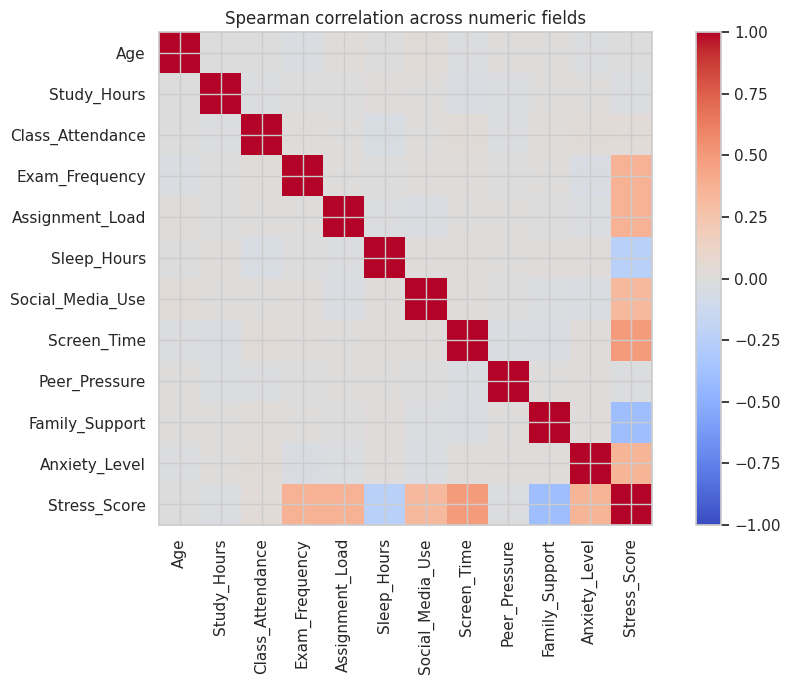

In [14]:
numeric = df.select_dtypes(include="number").columns.tolist()
display(df[numeric].describe().T)
fig,ax=plt.subplots(figsize=(10,7))
corr=df[numeric].corr(method="spearman"); im=ax.imshow(corr,vmin=-1,vmax=1,cmap="coolwarm"); ax.set_xticks(range(len(numeric)),numeric,rotation=90);ax.set_yticks(range(len(numeric)),numeric);fig.colorbar(im,ax=ax)
ax.set_title("Spearman correlation across numeric fields")
plt.tight_layout();plt.show()

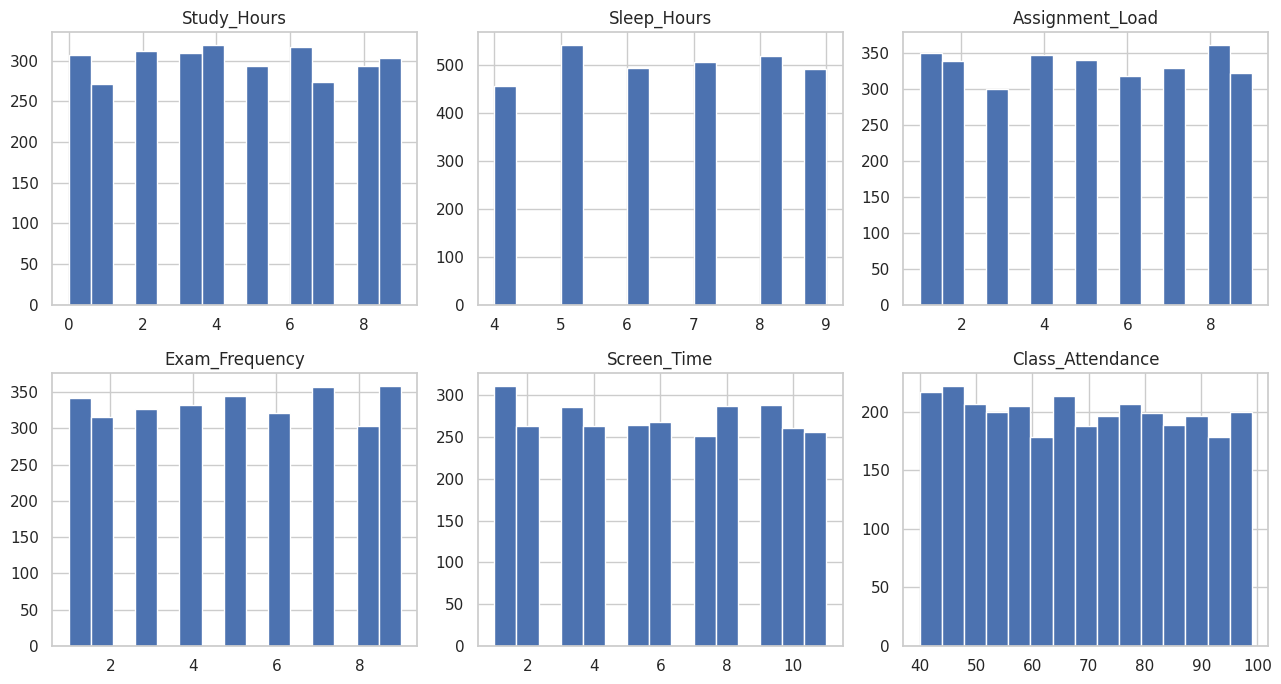

In [15]:
fig,axs=plt.subplots(2,3,figsize=(13,7))
for ax,c in zip(axs.flat,["Study_Hours","Sleep_Hours","Assignment_Load","Exam_Frequency","Screen_Time","Class_Attendance"]):
    ax.hist(df[c].dropna(),bins=15)
    ax.set_title(c)
plt.tight_layout();plt.show()

### Stress-score construction check
The class label is derived from the stress score, so never use `Stress_Score` as a predictor of `Stress_Level`. If the score itself was computed from other features, using those features may also reconstruct the label.

In [16]:
display(pd.crosstab(df["Stress_Score"],df["Stress_Level"]))
print("Range of score within each class:")
display(df.groupby("Stress_Level")["Stress_Score"].agg(["min","max","count"]))
print("A score directly determines a category if each score maps to only one stress class:", (df.groupby("Stress_Score")["Stress_Level"].nunique()<=1).all())

Stress_Level,High,Low,Medium
Stress_Score,,,
-9,0,1,0
-8,0,3,0
-7,0,4,0
-6,0,5,0
-5,0,5,0
-4,0,11,0
-3,0,18,0
-2,0,22,0
-1,0,41,0


Range of score within each class:


,min,max,count
Stress_Level,,,
High,21,33,326
Low,-9,10,1243
Medium,11,20,1431


A score directly determines a category if each score maps to only one stress class: True


### Optional — Original six-factor boxplot (for comparison)

### Numeric factor vs reported stress classes
Boxplots display how factor distributions vary across the **constructed** stress classes; not independent validation.

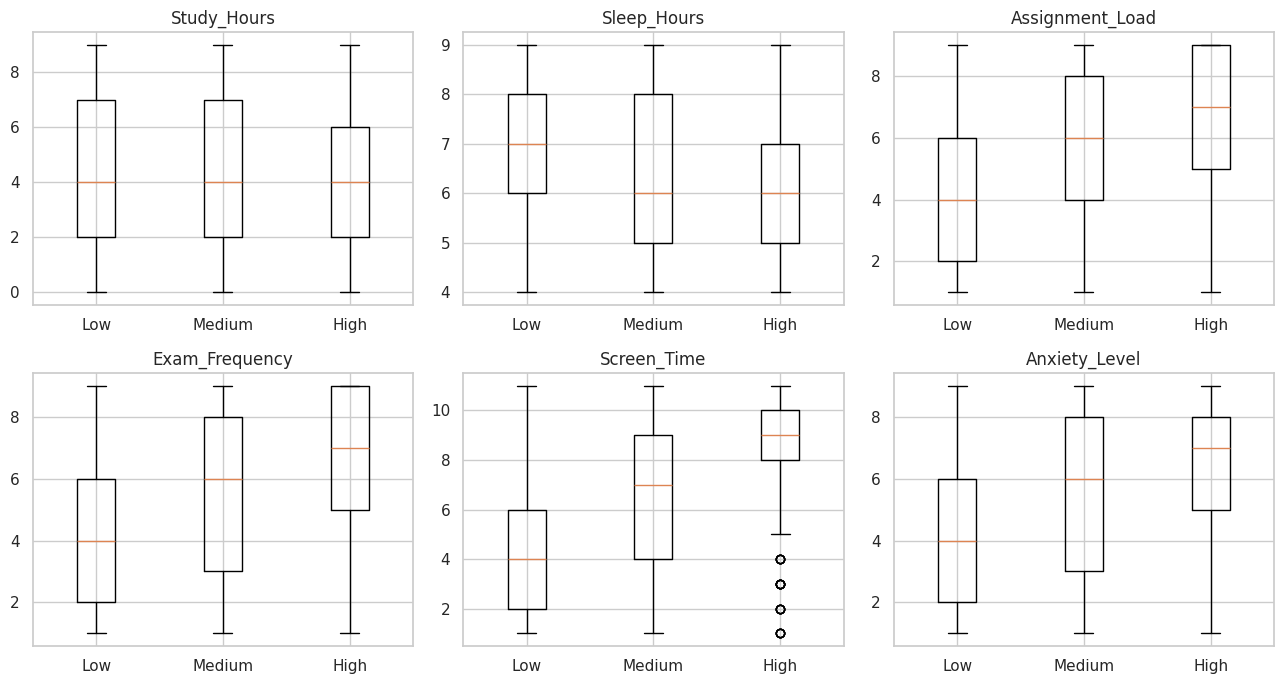

In [17]:
fig,axs=plt.subplots(2,3,figsize=(13,7))
for ax,c in zip(axs.flat,["Study_Hours","Sleep_Hours","Assignment_Load","Exam_Frequency","Screen_Time","Anxiety_Level"]):
    ax.boxplot([df.loc[df["Stress_Level"]==level,c].dropna() for level in ["Low","Medium","High"]],tick_labels=["Low","Medium","High"])
    ax.set_title(c)
plt.tight_layout();plt.show()

In [18]:
def stress_crosstab(feature, target_col=target, order=None, figsize=(10,4)):
    tab = pd.crosstab(df[feature].fillna("Missing"), df[target_col], dropna=False)
    if order is not None:
        tab = tab.reindex([x for x in order if x in tab.index])
    if tab.empty: return
    display(tab)
    pct = tab.div(tab.sum(axis=1).replace(0,np.nan), axis=0)*100
    ax=pct.plot(kind="bar", stacked=True, figsize=figsize, width=.82)
    ax.set(title=f"Stress distribution by {feature}",xlabel=feature,ylabel="Within-group percentage (%)")
    ax.legend(title="Stress",bbox_to_anchor=(1.01,1),loc="upper left")
    plt.xticks(rotation=30,ha="right"); plt.tight_layout();plt.show()
    if (tab.sum(axis=1)<10).any(): print("Caution: at least one subgroup has fewer than 10 respondents.")

def categorical_association(feature):
    tab=pd.crosstab(df[feature],df[target])
    if min(tab.shape)<2: return {"feature":feature,"cramers_v":np.nan,"p_value":np.nan,"min_group":int(tab.sum(axis=1).min())}
    chi2,p,_,expected=chi2_contingency(tab)
    n=tab.values.sum(); v=np.sqrt((chi2/n)/min(tab.shape[0]-1,tab.shape[1]-1))
    return {"feature":feature,"cramers_v":round(float(v),3),"p_value":round(float(p),5),"min_group":int(tab.sum(axis=1).min()),"expected_lt_5":int((expected<5).sum())}


Factor: Physical_Exercise


Stress_Level,High,Low,Medium
Physical_Exercise,,,
No,205,545,801
Yes,121,698,630


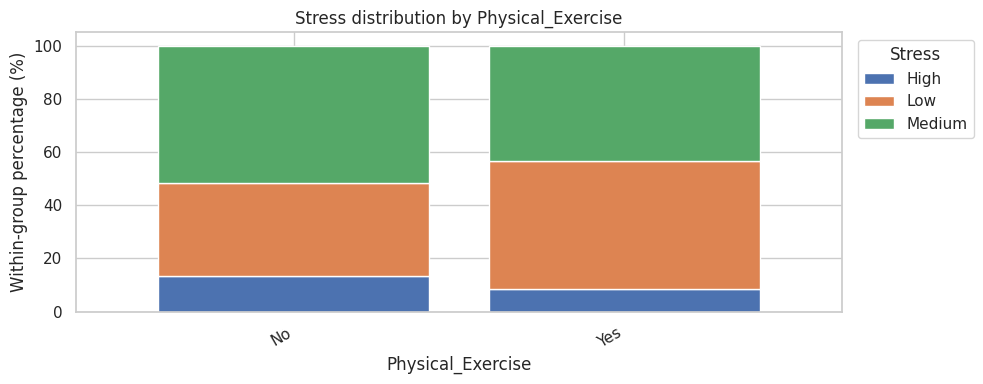


Factor: Gender


Stress_Level,High,Low,Medium
Gender,,,
Female,167,653,718
Male,159,590,713


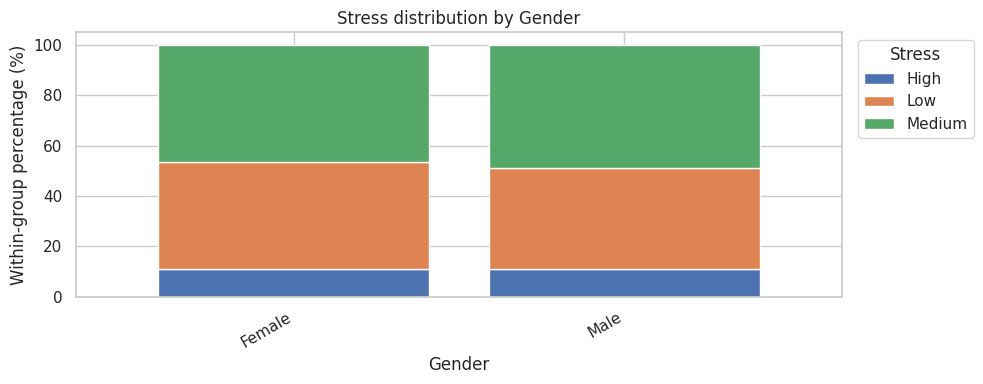


Factor: Family_Income_Level


Stress_Level,High,Low,Medium
Family_Income_Level,,,
High,70,266,272
Low,118,427,514
Medium,138,550,645


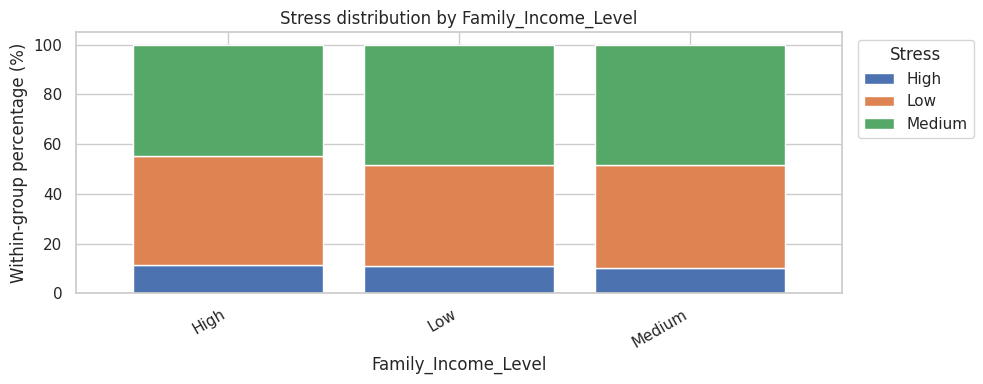


Factor: University_Type


Stress_Level,High,Low,Medium
University_Type,,,
National University,111,417,472
Private University,94,409,494
Public University,121,417,465


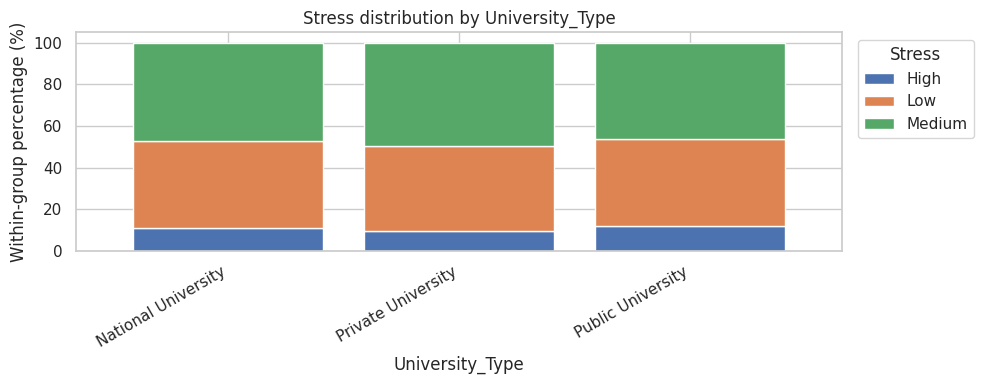

In [19]:
for feat in ["Physical_Exercise","Gender","Family_Income_Level","University_Type"]:
    print("\nFactor:",feat)
    stress_crosstab(feat)

## 7 — Optional advanced association statistics from your original notebook
Cramér's V is beyond basic data visualization. This section is **kept intact** so you don't lose your original work, but it is not required to explain the main workflow and it does not estimate model weights.

## 4 — Categorical association screening
Cramér’s V summarizes *strength of association* in contingency tables (0 means no association). It is **not** an ML feature weight or a causal effect. Chi-square p-values are exploratory and unreliable when expected counts are small; don't treat them as proof after testing many features. Correlated variables and sample-size differences complicate comparisons across datasets.

,feature,cramers_v,p_value,min_group,expected_lt_5
0,Physical_Exercise,0.138,0.00000,1449,0
4,University_Type,0.027,0.34523,997,0
3,Family_Income_Level,0.023,0.53272,608,0
2,Tuition,0.022,0.48742,1455,0
1,Gender,0.022,0.47652,1462,0


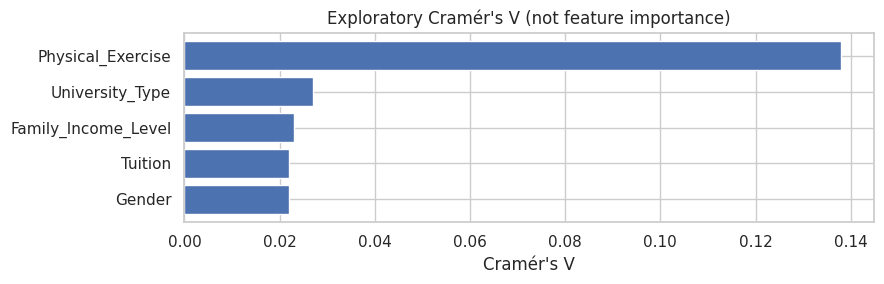

Caution: expected_lt_5 > 0 means standard chi-square approximation may be unreliable.


In [20]:
features = ['Physical_Exercise', 'Gender', 'Tuition', 'Family_Income_Level', 'University_Type']
assoc = pd.DataFrame([categorical_association(c) for c in features]).sort_values("cramers_v",ascending=False)
display(assoc)
fig, ax = plt.subplots(figsize=(9,max(3, len(assoc)*.43)))
ax.barh(assoc["feature"], assoc["cramers_v"]); ax.invert_yaxis()
ax.set(title="Exploratory Cramér's V (not feature importance)",xlabel="Cramér's V",ylabel="")
plt.tight_layout();plt.show()
print("Caution: expected_lt_5 > 0 means standard chi-square approximation may be unreliable.")

## 8 — Summary and next steps
Describe: which patterns you observed, which factors you **provisionally** retained and why, whether some categories had few observations, and especially how the calculated target limits interpretation.

**Do not report selected factors as proven useful until you test models on unseen data.**

## 5 — Automatic descriptive findings for the progress report
This prints **actual observations**; they are descriptive and not claims of statistical significance. Avoid translating category order to numerical quantities without confirming the questionnaire.

In [21]:
major = df[target].value_counts()
print(f"Observed sample size: {len(df):,}, with {df.shape[1]} columns.")
print(f"Missing cells: {df.isna().sum().sum()}, exact duplicate rows: {df.duplicated().sum()}.")
print(f"Most frequent stress category: {major.index[0]} ({major.iloc[0]} / {len(df)}, {major.iloc[0]/len(df):.1%}).")
for f in ['Physical_Exercise', 'Gender', 'Family_Income_Level']:
    tab=pd.crosstab(df[f],df[target]); pct=tab.div(tab.sum(axis=1),axis=0)*100
    print(f"{f}: {len(tab)} observed groups; smallest group size = {tab.sum(axis=1).min()}.")
print("Report limitations: self-report, cross-sectional associations, sample representativeness, target measurement differences.")

Observed sample size: 3,000, with 18 columns.
Missing cells: 0, exact duplicate rows: 0.
Most frequent stress category: Medium (1431 / 3000, 47.7%).
Physical_Exercise: 2 observed groups; smallest group size = 1449.
Gender: 2 observed groups; smallest group size = 1462.


Family_Income_Level: 3 observed groups; smallest group size = 608.
Report limitations: self-report, cross-sectional associations, sample representativeness, target measurement differences.


## 6 — Summary and decision notes

**For the progress report:** Export the most informative charts, record the direction of differences for compatible variables, and discuss small sample groups and stress-target limitations. Do not call a high association evidence of causation.

**Next step:** Compare this notebook with the other two notebooks. Pick a prediction dataset based on measurement validity, feature completeness, class balance, leakage risk, and preliminary cross-validated results. No dataset is automatically selected at this stage.